<a href="https://colab.research.google.com/github/ayoosarah203-glitch/GEO2-UTM-ENGINE/blob/main/GROUP_THREE_WORK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== STEP 1: INITIAL GEOGRAPHIC DATASET (LAT/LONG) ===
  Point_ID  Latitude  Longitude
0     P001    0.3476    32.5825
1     P002    0.3521    32.5890
2     P003    0.3589    32.5955
3     P004    0.3610    32.6010
4     P005    0.3655    32.6085
5     P006    0.3702    32.6142
6     P007    0.3748    32.6201
7     P008    0.3801    32.6278

=== STEP 2: CONVERTING TO UTM GRID COORDINATES ===
  Point_ID  Latitude  Longitude  UTM_Easting_m  UTM_Northing_m  UTM_Zone  \
0     P001    0.3476    32.5825     453543.138       38421.276        36   
1     P002    0.3521    32.5890     454266.453       38918.642        36   
2     P003    0.3589    32.5955     454989.778       39670.234        36   
3     P004    0.3610    32.6010     455601.804       39902.326        36   
4     P005    0.3655    32.6085     456436.391       40399.687        36   
5     P006    0.3702    32.6142     457070.683       40919.163        36   
6     P007    0.3748    32.6201     457727.228       41427.584        36  

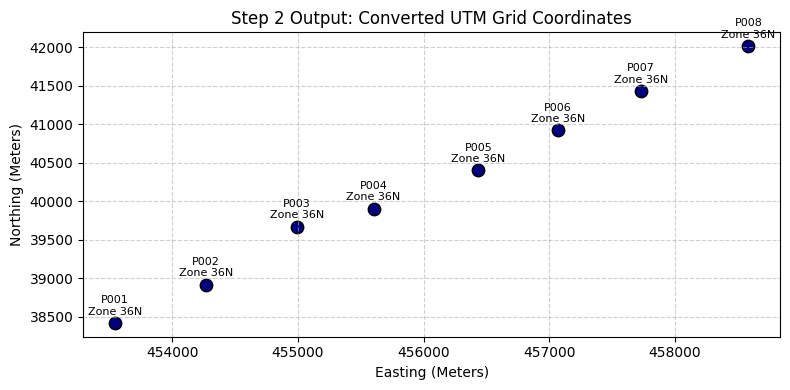


=== STEP 3: REVERSING FROM UTM BACK TO GEOGRAPHIC ===
  Point_ID  UTM_Easting_m  UTM_Northing_m  Latitude  Calculated_Latitude  \
0     P001     453543.138       38421.276    0.3476               0.3476   
1     P002     454266.453       38918.642    0.3521               0.3521   
2     P003     454989.778       39670.234    0.3589               0.3589   
3     P004     455601.804       39902.326    0.3610               0.3610   
4     P005     456436.391       40399.687    0.3655               0.3655   
5     P006     457070.683       40919.163    0.3702               0.3702   
6     P007     457727.228       41427.584    0.3748               0.3748   
7     P008     458584.071       42013.369    0.3801               0.3801   

   Lat_Diff  Longitude  Calculated_Longitude  Lon_Diff  
0       0.0    32.5825               32.5825       0.0  
1       0.0    32.5890               32.5890       0.0  
2       0.0    32.5955               32.5955       0.0  
3       0.0    32.6010          

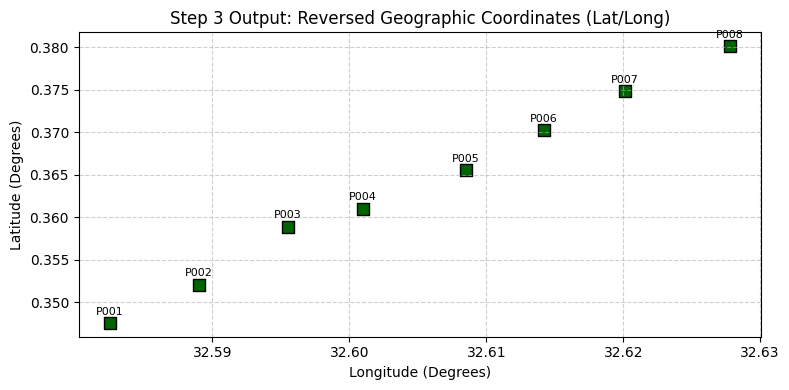

In [6]:
import pandas as pd
import pyproj
import matplotlib.pyplot as plt


class UTMTransformationPipeline:
    """
    Automated Geomatics Pipeline for Bidirectional UTM/Geographic
    Coordinate Transformations, Batch Processing, and Residual Analysis.
    """

    def __init__(self, geographic_crs="EPSG:4326"):
        """Initializes pipeline with base WGS84 Geographic CRS."""
        self.geographic_crs = geographic_crs

    def get_utm_epsg(self, lat: float, lon: float) -> tuple[int, str, str]:
        """Determines UTM Zone, Hemisphere, and corresponding EPSG Code."""
        zone = int((lon + 180) // 6) + 1
        is_northern = lat >= 0
        hemisphere = "N" if is_northern else "S"
        epsg_code = f"EPSG:{32600 + zone}" if is_northern else f"EPSG:{32700 + zone}"
        return zone, hemisphere, epsg_code

    def step1_forward_convert(self, df: pd.DataFrame) -> pd.DataFrame:
        """Converts raw Geographic coordinates (Lat/Long) to UTM (Easting/Northing)."""
        eastings, northings, zones, hemispheres, epsgs = [], [], [], [], []

        for _, row in df.iterrows():
            lat, lon = row["Latitude"], row["Longitude"]
            zone, hemi, target_epsg = self.get_utm_epsg(lat, lon)

            transformer = pyproj.Transformer.from_crs(
                self.geographic_crs, target_epsg, always_xy=True
            )
            easting, northing = transformer.transform(lon, lat)

            eastings.append(round(easting, 3))
            northings.append(round(northing, 3))
            zones.append(zone)
            hemispheres.append(hemi)
            epsgs.append(target_epsg)

        df_res = df.copy()
        df_res["UTM_Easting_m"] = eastings
        df_res["UTM_Northing_m"] = northings
        df_res["UTM_Zone"] = zones
        df_res["Hemisphere"] = hemispheres
        df_res["EPSG_Code"] = epsgs
        return df_res

    def step2_reverse_convert(self, df_utm: pd.DataFrame) -> pd.DataFrame:
        """Converts UTM dataset directly back to Geographic coordinates (Lat/Long)."""
        calc_lats, calc_lons = [], []

        for _, row in df_utm.iterrows():
            easting = row["UTM_Easting_m"]
            northing = row["UTM_Northing_m"]
            zone = int(row["UTM_Zone"])
            hemi = row["Hemisphere"]

            epsg_code = f"EPSG:{32600 + zone}" if hemi == "N" else f"EPSG:{32700 + zone}"
            transformer = pyproj.Transformer.from_crs(
                epsg_code, self.geographic_crs, always_xy=True
            )
            lon, lat = transformer.transform(easting, northing)

            calc_lats.append(round(lat, 6))
            calc_lons.append(round(lon, 6))

        df_res = df_utm.copy()
        df_res["Calculated_Latitude"] = calc_lats
        df_res["Calculated_Longitude"] = calc_lons
        return df_res


def main():
    pipeline = UTMTransformationPipeline()

    # STEP 1: INITIAL INPUT DATASET
    print("=== STEP 1: INITIAL GEOGRAPHIC DATASET (LAT/LONG) ===")
    input_data = pd.DataFrame({
        'Point_ID': ['P001', 'P002', 'P003', 'P004', 'P005', 'P006', 'P007', 'P008'],
        'Latitude':  [0.347600, 0.352100, 0.358900, 0.361000, 0.365500, 0.370200, 0.374800, 0.380100],
        'Longitude': [32.582500, 32.589000, 32.595500, 32.601000, 32.608500, 32.614200, 32.620100, 32.627800]
    })
    print(input_data)

    # STEP 2: FORWARD CONVERSION
    print("\n=== STEP 2: CONVERTING TO UTM GRID COORDINATES ===")
    utm_dataset = pipeline.step1_forward_convert(input_data)
    print(utm_dataset[['Point_ID', 'Latitude', 'Longitude', 'UTM_Easting_m', 'UTM_Northing_m', 'UTM_Zone', 'Hemisphere', 'EPSG_Code']])
    utm_dataset.to_csv("step2_utm_converted_output.csv", index=False)

    # Plot Forward Results
    plt.figure(figsize=(8, 4))
    plt.scatter(
        utm_dataset['UTM_Easting_m'], utm_dataset['UTM_Northing_m'],
        c='navy', s=80, edgecolors='black'
    )
    for _, row in utm_dataset.iterrows():
        plt.annotate(
            f"{row['Point_ID']}\nZone {row['UTM_Zone']}{row['Hemisphere']}",
            (row['UTM_Easting_m'], row['UTM_Northing_m']),
            textcoords="offset points", xytext=(0, 6), ha='center', fontsize=8
        )
    plt.title("Step 2 Output: Converted UTM Grid Coordinates")
    plt.xlabel("Easting (Meters)")
    plt.ylabel("Northing (Meters)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    # STEP 3: REVERSE CONVERSION & RESIDUAL CHECK
    print("\n=== STEP 3: REVERSING FROM UTM BACK TO GEOGRAPHIC ===")
    final_dataset = pipeline.step2_reverse_convert(utm_dataset)

    # Residual Error Calculation
    final_dataset['Lat_Diff'] = round(final_dataset['Calculated_Latitude'] - final_dataset['Latitude'], 6)
    final_dataset['Lon_Diff'] = round(final_dataset['Calculated_Longitude'] - final_dataset['Longitude'], 6)

    print(final_dataset[['Point_ID', 'UTM_Easting_m', 'UTM_Northing_m', 'Latitude', 'Calculated_Latitude', 'Lat_Diff', 'Longitude', 'Calculated_Longitude', 'Lon_Diff']])
    final_dataset.to_csv("Final_bidirectional_pipeline_results.csv", index=False)

    # Plot Reverse Results
    plt.figure(figsize=(8, 4))
    plt.scatter(
        final_dataset['Calculated_Longitude'], final_dataset['Calculated_Latitude'],
        c='darkgreen', marker='s', s=80, edgecolors='black'
    )
    for _, row in final_dataset.iterrows():
        plt.annotate(
            f"{row['Point_ID']}",
            (row['Calculated_Longitude'], row['Calculated_Latitude']),
            textcoords="offset points", xytext=(0, 6), ha='center', fontsize=8
        )
    plt.title("Step 3 Output: Reversed Geographic Coordinates (Lat/Long)")
    plt.xlabel("Longitude (Degrees)")
    plt.ylabel("Latitude (Degrees)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()

In [15]:
%%writefile app.py
import streamlit as st
import pandas as pd
import pyproj
import matplotlib.pyplot as plt

# Set Page Configuration
st.set_page_config(
    page_title="GEO2UTM-ENGINE Dashboard",
    page_icon="🌐",
    layout="wide"
)

# --- PIPELINE CLASS ---
class UTMTransformationPipeline:
    def __init__(self, geographic_crs="EPSG:4326"):
        self.geographic_crs = geographic_crs

    def get_utm_epsg(self, lat: float, lon: float):
        zone = int((lon + 180) // 6) + 1
        is_northern = lat >= 0
        hemisphere = "N" if is_northern else "S"
        epsg_code = f"EPSG:{32600 + zone}" if is_northern else f"EPSG:{32700 + zone}"
        return zone, hemisphere, epsg_code

    def step1_forward_convert(self, df: pd.DataFrame) -> pd.DataFrame:
        eastings, northings, zones, hemispheres, epsgs = [], [], [], [], []
        for _, row in df.iterrows():
            lat, lon = row["Latitude"], row["Longitude"]
            zone, hemi, target_epsg = self.get_utm_epsg(lat, lon)
            transformer = pyproj.Transformer.from_crs(self.geographic_crs, target_epsg, always_xy=True)
            easting, northing = transformer.transform(lon, lat)
            eastings.append(round(easting, 3))
            northings.append(round(northing, 3))
            zones.append(zone)
            hemispheres.append(hemi)
            epsgs.append(target_epsg)

        df_res = df.copy()
        df_res["UTM_Easting_m"] = eastings
        df_res["UTM_Northing_m"] = northings
        df_res["UTM_Zone"] = zones
        df_res["Hemisphere"] = hemispheres
        df_res["EPSG_Code"] = epsgs
        return df_res

    def step2_reverse_convert(self, df_utm: pd.DataFrame) -> pd.DataFrame:
        calc_lats, calc_lons = [], []
        for _, row in df_utm.iterrows():
            easting = row["UTM_Easting_m"]
            northing = row["UTM_Northing_m"]
            zone = int(row["UTM_Zone"])
            hemi = row["Hemisphere"]
            epsg_code = f"EPSG:{32600 + zone}" if hemi == "N" else f"EPSG:{32700 + zone}"
            transformer = pyproj.Transformer.from_crs(epsg_code, self.geographic_crs, always_xy=True)
            lon, lat = transformer.transform(easting, northing)
            calc_lats.append(round(lat, 6))
            calc_lons.append(round(lon, 6))

        df_res = df_utm.copy()
        df_res["Calculated_Latitude"] = calc_lats
        df_res["Calculated_Longitude"] = calc_lons
        return df_res


pipeline = UTMTransformationPipeline()

# --- DASHBOARD UI ---
st.title("🌐 GEO2UTM-ENGINE: Spatial Transformation Dashboard")
st.markdown("Automated Geomatics Pipeline for **Bidirectional UTM/Geographic Transformations**, **Batch Processing**, and **Residual Accuracy Analysis**.")

tab1, tab2, tab3 = st.tabs(["📊 Batch File Processing", "📍 Single Point Converter", "📘 Project Info & Documentation"])

# TAB 1: BATCH PROCESSING
with tab1:
    st.subheader("Batch Coordinate Transformation & Analysis")
    data_source = st.radio("Select Input Source:", ["Use Default Control Points Network (8 Points)", "Upload Custom CSV File"], horizontal=True)

    if data_source == "Upload Custom CSV File":
        uploaded_file = st.file_uploader("Upload CSV File (Required columns: 'Point_ID', 'Latitude', 'Longitude')", type=["csv"])
        input_df = pd.read_csv(uploaded_file) if uploaded_file is not None else None
    else:
        input_df = pd.DataFrame({
            'Point_ID': ['P001', 'P002', 'P003', 'P004', 'P005', 'P006', 'P007', 'P008'],
            'Latitude':  [0.347600, 0.352100, 0.358900, 0.361000, 0.365500, 0.370200, 0.374800, 0.380100],
            'Longitude': [32.582500, 32.589000, 32.595500, 32.601000, 32.608500, 32.614200, 32.620100, 32.627800]
        })

    if input_df is not None:
        st.markdown("### Step 1: Input Geographic Dataset")
        st.dataframe(input_df, use_container_width=True)

        if st.button("🚀 Run Complete Transformation Pipeline", type="primary"):
            utm_df = pipeline.step1_forward_convert(input_df)
            final_df = pipeline.step2_reverse_convert(utm_df)
            final_df['Lat_Diff'] = round(final_df['Calculated_Latitude'] - final_df['Latitude'], 6)
            final_df['Lon_Diff'] = round(final_df['Calculated_Longitude'] - final_df['Longitude'], 6)

            st.success("Transformation Completed Successfully!")

            col1, col2, col3, col4 = st.columns(4)
            col1.metric("Total Points", len(final_df))
            col2.metric("UTM Zone", f"{final_df['UTM_Zone'].iloc[0]}{final_df['Hemisphere'].iloc[0]}")
            col3.metric("Max ΔLat", f"{final_df['Lat_Diff'].abs().max():.6f}°")
            col4.metric("Max ΔLon", f"{final_df['Lon_Diff'].abs().max():.6f}°")

            st.markdown("### Step 2: Forward UTM Transformation Output")
            st.dataframe(utm_df[['Point_ID', 'Latitude', 'Longitude', 'UTM_Easting_m', 'UTM_Northing_m', 'UTM_Zone', 'Hemisphere', 'EPSG_Code']], use_container_width=True)

            st.markdown("### Step 3: Reverse Transformation & Residual Error Analysis")
            st.dataframe(final_df[['Point_ID', 'UTM_Easting_m', 'UTM_Northing_m', 'Latitude', 'Calculated_Latitude', 'Lat_Diff', 'Longitude', 'Calculated_Longitude', 'Lon_Diff']], use_container_width=True)

            st.download_button(
                label="📥 Download Converted Dataset (CSV)",
                data=final_df.to_csv(index=False).encode('utf-8'),
                file_name="Final_bidirectional_pipeline_results.csv",
                mime="text/csv"
            )

            fig_col1, fig_col2 = st.columns(2)
            with fig_col1:
                fig1, ax1 = plt.subplots(figsize=(6, 4))
                ax1.scatter(utm_df['UTM_Easting_m'], utm_df['UTM_Northing_m'], c='navy', s=70, edgecolors='black')
                for _, row in utm_df.iterrows():
                    ax1.annotate(row['Point_ID'], (row['UTM_Easting_m'], row['UTM_Northing_m']), textcoords="offset points", xytext=(0, 5), ha='center', fontsize=8)
                ax1.set_title("Converted UTM Grid Coordinates")
                ax1.set_xlabel("Easting (m)")
                ax1.set_ylabel("Northing (m)")
                ax1.grid(True, linestyle='--', alpha=0.6)
                st.pyplot(fig1)

            with fig_col2:
                fig2, ax2 = plt.subplots(figsize=(6, 4))
                ax2.scatter(final_df['Calculated_Longitude'], final_df['Calculated_Latitude'], c='darkgreen', marker='s', s=70, edgecolors='black')
                for _, row in final_df.iterrows():
                    ax2.annotate(row['Point_ID'], (row['Calculated_Longitude'], row['Calculated_Latitude']), textcoords="offset points", xytext=(0, 5), ha='center', fontsize=8)
                ax2.set_title("Reversed Geographic Coordinates")
                ax2.set_xlabel("Longitude (°)")
                ax2.set_ylabel("Latitude (°)")
                ax2.grid(True, linestyle='--', alpha=0.6)
                st.pyplot(fig2)

# TAB 2: SINGLE POINT CONVERTER
with tab2:
    st.subheader("Interactive Single-Point Converter")
    c1, c2 = st.columns(2)
    with c1:
        st.markdown("#### Geographic to UTM")
        lat_in = st.number_input("Latitude (°)", value=0.347600, format="%.6f")
        lon_in = st.number_input("Longitude (°)", value=32.582500, format="%.6f")
        if st.button("Convert to UTM"):
            z, h, epsg = pipeline.get_utm_epsg(lat_in, lon_in)
            transformer = pyproj.Transformer.from_crs("EPSG:4326", epsg, always_xy=True)
            e, n = transformer.transform(lon_in, lat_in)
            st.success(f"**Easting:** {e:.3f} m | **Northing:** {n:.3f} m")
            st.info(f"**UTM Zone:** {z}{h} | **EPSG Code:** {epsg}")

    with c2:
        st.markdown("#### UTM to Geographic")
        east_in = st.number_input("Easting (m)", value=453543.138, format="%.3f")
        north_in = st.number_input("Northing (m)", value=38421.276, format="%.3f")
        zone_in = st.number_input("UTM Zone", value=36, min_value=1, max_value=60)
        hemi_in = st.selectbox("Hemisphere", ["N", "S"])
        if st.button("Convert to Geographic"):
            epsg = f"EPSG:{32600 + zone_in}" if hemi_in == "N" else f"EPSG:{32700 + zone_in}"
            transformer = pyproj.Transformer.from_crs(epsg, "EPSG:4326", always_xy=True)
            lon_out, lat_out = transformer.transform(east_in, north_in)
            st.success(f"**Latitude:** {lat_out:.8f}° | **Longitude:** {lon_out:.8f}°")

# TAB 3: DOCUMENTATION
with tab3:
    st.subheader("Project Information & Specifications")
    st.markdown("""
    - **Geodetic Datum:** WGS 84 (EPSG:4326)
    - **Projection System:** Universal Transverse Mercator (UTM, 6° Longitudinal Zones)
    - **Zone Resolution Formula:** $\\text{Zone} = \\lfloor(\\text{Longitude} + 180) / 6\\rfloor + 1$
    - **Dynamic EPSG:** EPSG:32601–32660 (Northern Hemisphere) / EPSG:32701–32760 (Southern Hemisphere)
    """)

Overwriting app.py


In [1]:
# 1. Install dependencies and Cloudflare Tunnel
!pip install -q streamlit pyproj pandas matplotlib
!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared

# 2. Launch Streamlit server and Cloudflare Tunnel concurrently
!./cloudflared tunnel --url http://localhost:8501 & streamlit run app.py &> /dev/null &

2026-11-08T06:10:23Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-08T06:10:23Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-08T06:10:27Z INF +--------------------------------------------------------------------------------------------+
2026-11-08T06:10:27Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-08T06:10:27Z INF |  https://lookup-voters-press-saturn.trycloudflare.com 